# 01. Particle Swarm Optimization

Sekawanan burung mencari makanan di sebuah lembah. Tidak ada burung yang tahu letak makanan, tetapi setiap burung ingat tempat terbaik yang pernah ia lewati dan bisa berkomunikasi dengan burung lain yang sedang berada di tempat paling menjanjikan bagi dia. Dengan dua informasi sederhana itu, kawanan pelan-pelan berkumpul di sekitar makanan.

**Particle Swarm Optimization (PSO)** meniru perilaku sekawanan burung atau ikan untuk mencari minimum sebuah fungsi. Notebook ini memakai animasi sederhana untuk memperlihatkan apa yang sebenarnya terjadi pada setiap langkah, lalu menurunkan rumusnya dan mengukur pengaruh tiap parameter.

Setelah praktikum ini, Anda diharapkan mampu:

1. menjelaskan istilah partikel, kecepatan, pbest, gbest, dan fitness;
2. menguraikan satu langkah update kecepatan menjadi komponen inersia, kognitif, dan sosial;
3. memilih parameter $w$, $c_1$, $c_2$ yang stabil berdasarkan syarat Poli dan faktor konstriksi Clerc;
4. membaca pengaruh parameter dari animasi dan dari eksperimen berulang;
5. mengimplementasikan PSO tervektorisasi dengan NumPy; serta
6. menjelaskan bagaimana topologi tetangga (gbest vs lbest cincin) memengaruhi konvergensi prematur.


> 
> [!TIP]
> **Recommended Visual Explanation**
>
> For a clearer, step-by-step visual explanation of this concept, watch this [YouTube video](https://www.youtube.com/watch?v=JhgDMAm-imI).
>

## Setup

In [1]:
import importlib.util
import shutil
import subprocess
import sys
from pathlib import Path

required = {"numpy": "numpy", "matplotlib": "matplotlib", "ipywidgets": "ipywidgets", "PIL": "pillow"}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)


def find_module_dir(start):
    """Find the folder that holds pso_lib.py."""
    for root in [start, *start.parents]:
        for candidate in (root, root / "Evolutionary Computation"):
            if (candidate / "pso_lib.py").exists():
                return candidate
        if (root / ".git").exists():
            break
    return None


module_dir = find_module_dir(Path.cwd())
if module_dir is None and "google.colab" in sys.modules:
    clone_dir = Path("Modul-Praktikum-KK-RKA-25")
    if not clone_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/kcv-if/Modul-Praktikum-KK-RKA-25.git", str(clone_dir)], check=True)
    module_dir = find_module_dir(clone_dir)
if module_dir is None:
    raise RuntimeError("pso_lib.py not found; open this notebook inside the repository")
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pso_lib as lib
from pso_lib import pso, rastrigin, sphere, RASTRIGIN_BOUNDS, CONFIGS

lib.apply_style()
np.set_printoptions(precision=4, suppress=True)

## 1.1 Gambaran Umum PSO

### Penjelasan

PSO diperkenalkan oleh Kennedy dan Eberhart pada 1995 [1]. Idenya berasal dari simulasi kawanan burung dan ikan: setiap individu bergerak sendiri, tetapi arah geraknya dipengaruhi pengalamannya sendiri dan pengalaman kelompok. Tidak ada gradien yang dihitung, sehingga PSO bisa dipakai untuk fungsi yang tidak mulus, punya banyak minimum lokal, atau hanya bisa dievaluasi sebagai kotak hitam.

| Istilah | Arti dalam PSO |
|---|---|
| Partikel | Satu kandidat solusi; posisinya $\mathbf{x}_i$ adalah titik di ruang pencarian |
| Kecepatan | Perpindahan $\mathbf{v}_i$ yang akan ditambahkan ke posisi pada langkah berikutnya |
| Fitness | Nilai fungsi tujuan $f(\mathbf{x}_i)$; di notebook ini makin kecil makin baik |
| pbest | *Personal best* $\mathbf{p}_i$, posisi terbaik yang pernah dikunjungi partikel $i$ |
| gbest | *Global best* $\mathbf{g}$, posisi terbaik yang pernah ditemukan seluruh kawanan |

Ada dua kebutuhan yang saling tarik. **Eksplorasi** berarti menjelajah daerah baru agar tidak terjebak di minimum lokal. **Eksploitasi** berarti memperhalus pencarian di sekitar solusi yang sudah bagus. Parameter PSO, yang dibahas di bagian 1.3 dan 1.4, pada dasarnya mengatur keseimbangan dua hal ini.

Fungsi uji yang dipakai adalah **Rastrigin**:

$$f(\mathbf{x}) = 10d + \sum_{j=1}^{d}\left(x_j^2 - 10\cos(2\pi x_j)\right),\qquad x_j\in[-5{,}12;\ 5{,}12].$$

Minimum globalnya $f(\mathbf{0})=0$, ditandai silang kecil pada peta. Di sekelilingnya ada banyak lembah kecil (minimum lokal) yang menjadi jebakan.

**Dibandingkan dengan Genetic Algorithm.** PSO dan GA sama-sama algoritma berbasis populasi, tetapi cara populasinya berubah sangat berbeda:

| Aspek | Genetic Algorithm | PSO |
|---|---|---|
| Anggota populasi | kromosom | partikel |
| Operator | seleksi, crossover, mutasi | update kecepatan lalu posisi |
| Siapa bertahan | hanya individu yang lolos seleksi | semua partikel tetap ada, hanya berpindah |
| Memori | tidak ada; individu lama digantikan keturunannya | setiap partikel ingat pbest, kawanan ingat gbest |
| Arah perubahan | kombinasi orang tua dan mutasi acak | terarah ke pbest dan gbest, dengan faktor acak |
| Representasi umum | sering biner atau diskret | vektor bilangan real |

Karena tidak ada individu yang dibuang, informasi di PSO menyebar lewat **memori** (pbest dan gbest), bukan lewat pewarisan gen.

### Contoh penerapan

Animasi berikut menjalankan 30 partikel selama 50 iterasi dengan parameter Clerc (dibahas di bagian 1.3). Titik gelap adalah partikel, ekornya adalah jejak beberapa langkah terakhir, dan bintang adalah gbest.

In [2]:
hero = pso(rastrigin, dim=2, bounds=RASTRIGIN_BOUNDS, n_particles=30, iters=50, seed=7, record=True)
print(f"gbest akhir = {hero['gbest']}, f = {hero['gbest_f']:.6f}")
lib.show_and_export(lib.animate_swarms([hero], rastrigin, RASTRIGIN_BOUNDS), "01_hero_rastrigin")

gbest akhir = [0.0008 0.0007], f = 0.000236


*Versi GIF*

![Animasi kawanan PSO pada Rastrigin 2D](figures/01_hero_rastrigin.gif)

Pada awalnya partikel tersebar merata dan gbest masih jauh dari pusat. Setelah beberapa iterasi kawanan tertarik ke lembah yang lebih dalam, langkahnya mengecil, dan akhirnya hampir semua partikel berkumpul di dekat silang.

## 1.2 Visualisasi Satu Langkah Update

### Penjelasan

Animasi tadi terlihat seperti gerakan kawanan yang rumit, padahal setiap partikel hanya mengikuti satu aturan. Kecepatan baru adalah jumlah tiga vektor:

$$\mathbf{v}_i^{t+1} = {\color{#3A7DCE}w\,\mathbf{v}_i^{t}} + {\color{#E8871E}c_1 r_1\,(\mathbf{p}_i-\mathbf{x}_i^{t})} + {\color{#C2185B}c_2 r_2\,(\mathbf{g}-\mathbf{x}_i^{t})}$$

$$\mathbf{x}_i^{t+1} = \mathbf{x}_i^{t} + {\color{#2E7D32}\mathbf{v}_i^{t+1}}$$

1. **Inersia** ${\color{#3A7DCE}w\,\mathbf{v}_i}$: partikel cenderung melanjutkan arah geraknya.
2. **Kognitif** ${\color{#E8871E}c_1 r_1(\mathbf{p}_i-\mathbf{x}_i)}$: tarikan ke posisi terbaik milik partikel itu sendiri.
3. **Sosial** ${\color{#C2185B}c_2 r_2(\mathbf{g}-\mathbf{x}_i)}$: tarikan ke posisi terbaik seluruh kawanan.

Ketiganya dijumlahkan secara ujung-ke-pangkal menjadi ${\color{#2E7D32}\mathbf{v}_i^{t+1}}$, lalu partikel berpindah sejauh vektor itu. Warna tiap suku pada rumus sama dengan warna panahnya di animasi.

### Contoh penerapan

Kawanan dari animasi sebelumnya dibekukan pada iterasi 3. Satu partikel dipilih, lalu setiap komponen kecepatan digambar satu per satu. Angka $r_1$ dan $r_2$ yang dipakai adalah angka acak yang benar-benar muncul pada run tersebut, sehingga ujung panah hijau tepat berada di posisi partikel pada iterasi 4. Sel juga mencetak angka setiap komponen, sehingga Anda bisa memeriksa panjang dan arah panah dengan tangan seperti pada Soal 1.

In [3]:
step_anim, particle = lib.animate_update_step(hero, rastrigin, RASTRIGIN_BOUNDS, t=3)
t, i, c1, c2 = 3, particle, hero["params"]["c1"], hero["params"]["c2"]
x, r1, r2 = hero["X"][t][i], hero["R1"][t][i], hero["R2"][t][i]
inertia = hero["W"][t] * hero["V"][t][i]
cognitive = c1 * r1 * (hero["P"][t][i] - x)
social = c2 * r2 * (hero["G"][t] - x)
print(f"partikel {i}, w = {hero['W'][t]:.4f}, r1 = {r1}, r2 = {r2}")
print(f"inersia  (biru)   = {inertia}")
print(f"kognitif (oranye) = {cognitive}")
print(f"sosial   (merah)  = {social}")
print(f"v baru   (hijau)  = {inertia + cognitive + social}")
print(f"x(3) = {x}  ->  x(4) = {hero['X'][t + 1][i]}")
lib.show_and_export(step_anim, "02_update_step")

partikel 20, w = 0.7298, r1 = [0.3766 0.6372], r2 = [0.9534 0.8862]
inersia  (biru)   = [ 0.6837 -1.4946]
kognitif (oranye) = [-0.5279  1.9524]
sosial   (merah)  = [-0.9672  1.0081]
v baru   (hijau)  = [-0.8114  1.4659]
x(3) = [ 2.653  -1.7843]  ->  x(4) = [ 1.8416 -0.3185]


*Versi GIF*

![Satu langkah update kecepatan](figures/02_update_step.gif)

**Kenapa panah oranye tidak menunjuk tepat ke pbest?** Garis putus-putus oranye adalah arah lurus dari partikel ke pbest, sedangkan panah oranye sedikit menyimpang darinya. Ini bukan kesalahan gambar. $r_1$ adalah **vektor** dengan satu angka acak untuk setiap dimensi, misalnya $r_1=(0{,}2;\ 0{,}9)$. Komponen $x$ dari $(\mathbf{p}_i-\mathbf{x}_i)$ dikali 0,2 dan komponen $y$ dikali 0,9, sehingga vektor hasilnya berputar menjauhi garis lurus ke pbest. Hal yang sama berlaku untuk panah merah muda terhadap gbest. Jika $r_1$ hanya satu angka untuk semua dimensi, panah selalu searah garis putus-putus dan hanya panjangnya yang berubah.

Perhatikan juga bahwa tidak ada komponen yang menunjuk langsung ke minimum global. Partikel hanya tahu tiga hal: arah lamanya, pbest-nya, dan gbest kawanan.

## 1.3 Model Matematis

### Penjelasan

Untuk partikel $i$ pada iterasi $t$, PSO standar (dengan bobot inersia dari Shi dan Eberhart [2]) memakai dua persamaan update:

$$\mathbf{v}_i^{t+1} = {\color{#3A7DCE}w\,\mathbf{v}_i^{t}} + {\color{#E8871E}c_1 r_1\,(\mathbf{p}_i-\mathbf{x}_i^{t})} + {\color{#C2185B}c_2 r_2\,(\mathbf{g}-\mathbf{x}_i^{t})}$$

$$\mathbf{x}_i^{t+1} = \mathbf{x}_i^{t} + {\color{#2E7D32}\mathbf{v}_i^{t+1}}$$

Perkalian dengan $r_1$ dan $r_2$ dilakukan per dimensi: setiap koordinat mendapat angka acak $U(0,1)$ sendiri. Setelah posisi baru dievaluasi, memori diperbarui (untuk minimisasi):

$$\mathbf{p}_i \leftarrow \begin{cases}\mathbf{x}_i^{t+1} & \text{jika } f(\mathbf{x}_i^{t+1}) < f(\mathbf{p}_i)\\ \mathbf{p}_i & \text{selainnya}\end{cases},\qquad \mathbf{g} \leftarrow \arg\min_{\mathbf{p}_i} f(\mathbf{p}_i).$$

| Simbol | Arti | Nilai umum |
|---|---|---|
| $\mathbf{x}_i^t$ | posisi partikel $i$ pada iterasi $t$ | acak seragam di dalam batas |
| $\mathbf{v}_i^t$ | kecepatan partikel $i$ | dibatasi $\pm v_{\max}$ |
| ${\color{#3A7DCE}w}$ | bobot inersia | 0,4 sampai 0,9 |
| ${\color{#E8871E}c_1}$ | koefisien kognitif | sekitar 1,5 |
| ${\color{#C2185B}c_2}$ | koefisien sosial | sekitar 1,5 |
| $r_1, r_2$ | angka acak $U(0,1)$ per dimensi | dibangkitkan ulang setiap langkah |
| $\mathbf{p}_i$ | pbest partikel $i$ | |
| $\mathbf{g}$ | gbest kawanan | |
| $v_{\max}$ | batas kecepatan per dimensi | $0{,}2\times$ lebar ruang pencarian |

**Bentuk pegas teredam.** Untuk melihat dinamika satu partikel, anggap $\mathbf{p}$ dan $\mathbf{g}$ tetap (kawanan sedang tidak menemukan hal baru), dan tulis satu dimensi saja (indeks $i$ dihilangkan). Definisikan

$$\kappa = c_1 r_1 + c_2 r_2,\qquad a = \frac{c_1 r_1\,p + c_2 r_2\,g}{\kappa}.$$

$\kappa$ adalah total tarikan dan $a$ adalah rata-rata berbobot pbest dan gbest. Dengan itu dua suku tarikan bisa digabung:

$$c_1 r_1(p-x^t) + c_2 r_2(g-x^t) = c_1 r_1 p + c_2 r_2 g - \kappa\,x^t = \kappa\,(a - x^t).$$

Update kecepatan menjadi $v^{t+1} = w\,v^t + \kappa(a-x^t)$. Karena $x^{t+1} = x^t + v^{t+1}$, kecepatan dapat ditulis sebagai selisih posisi: $v^{t+1} = x^{t+1}-x^t$ dan $v^t = x^t - x^{t-1}$. Substitusi keduanya:

$$x^{t+1} - x^t = w\,(x^t - x^{t-1}) + \kappa\,(a - x^t)$$

$$x^{t+1} = (1 + w - \kappa)\,x^t - w\,x^{t-1} + \kappa\,a.$$

Ini persamaan beda orde dua: posisi berikutnya bergantung pada **dua** posisi sebelumnya, persis seperti massa pada pegas. $\kappa$ adalah kekakuan pegas yang menarik partikel ke titik tarik $\mathbf{a}$ (rata-rata berbobot pbest dan gbest), sedangkan $w$ menentukan seberapa besar momentum dipertahankan. $w$ kecil berarti redaman kuat, sehingga partikel cepat berhenti. $w$ mendekati 1 berarti redaman lemah, sehingga partikel berosilasi lama di sekitar $\mathbf{a}$.

**Syarat stabilitas.** Karena $r_1, r_2$ acak, posisi partikel adalah variabel acak. Poli [3] menurunkan syarat agar rata-rata **dan** varians posisi konvergen. Inilah arti *stabil orde-2*: dalam jangka panjang partikel tidak hanya rata-ratanya menuju satu titik, tetapi sebarannya di sekitar titik itu juga berhenti membesar. Syaratnya:

$$-1 < w < 1,\qquad 0 < c_1 + c_2 < \frac{24(1-w^2)}{7-5w}.$$

**Faktor konstriksi Clerc.** Clerc dan Kennedy [4] menulis update dengan faktor pengali $\chi$:

$$\mathbf{v}^{t+1} = \chi\left(\mathbf{v}^{t} + c_1 r_1(\mathbf{p}-\mathbf{x}) + c_2 r_2(\mathbf{g}-\mathbf{x})\right),\qquad \chi = \frac{2}{\left|2-\varphi-\sqrt{\varphi^2-4\varphi}\right|},\quad \varphi = c_1+c_2 > 4.$$

Simbol $\varphi$ di sini adalah jumlah koefisien $c_1+c_2$ (konstanta), berbeda dengan $\kappa = c_1r_1+c_2r_2$ pada bentuk pegas yang ikut acak.

Dengan $\varphi = 4{,}1$ diperoleh $\chi \approx 0{,}7298$. Bentuk ini setara dengan PSO inersia biasa dengan $w = \chi \approx 0{,}7298$ dan $c_1 = c_2 = \chi\cdot 2{,}05 \approx 1{,}49618$. Nilai inilah yang menjadi bawaan fungsi `pso()` di notebook ini.

### Contoh penerapan

Sel berikut menghitung $\chi$, memeriksa bahwa pasangan Clerc berada di dalam daerah stabil, lalu menggambar daerah stabil beserta setiap pengaturan parameter yang dipakai di bagian 1.4.

chi = 0.7298, c1 = c2 = 1.49618
seimbang           w=0.7  c1+c2=3.0  batas=3.497  stabil=True
w kecil            w=0.2  c1+c2=3.0  batas=3.840  stabil=True
w besar            w=1.0  c1+c2=3.0  batas=0.000  stabil=False
kognitif dominan   w=0.7  c1+c2=3.0  batas=3.497  stabil=True
sosial dominan     w=0.7  c1+c2=3.0  batas=3.497  stabil=True
w turun 0.9→0.4    w=0.9  c1+c2=3.0  batas=1.824  stabil=False
w turun 0.9→0.4    w=0.4  c1+c2=3.0  batas=4.032  stabil=True


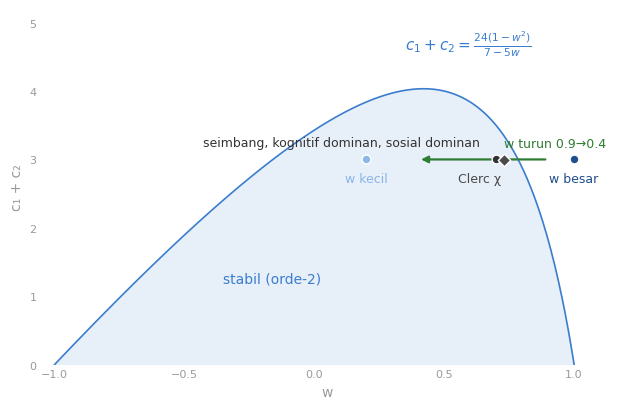

In [4]:
def poli_bound(w):
    return 24 * (1 - w**2) / (7 - 5 * w)


phi = 4.1
chi = 2 / abs(2 - phi - np.sqrt(phi**2 - 4 * phi))
print(f"chi = {chi:.4f}, c1 = c2 = {chi * phi / 2:.5f}")
assert np.isclose(chi, 0.7298, atol=1e-4)

for cfg in CONFIGS:
    for w in {cfg["w"], cfg["w_end"] or cfg["w"]}:
        c = cfg["c1"] + cfg["c2"]
        stable = -1 < w < 1 and 0 < c < poli_bound(w)
        print(f"{cfg['label']:<18} w={w:<4} c1+c2={c:<4} batas={poli_bound(w):.3f}  stabil={stable}")
lib.plot_stability(CONFIGS);

Pengaturan seimbang, kognitif dominan, dan sosial dominan punya $c_1+c_2=3$ dan $w=0{,}7$, sehingga berada di titik yang sama dan di dalam daerah stabil. Ketiganya hanya berbeda pada pembagian tarikan antara pbest dan gbest, yang tidak terlihat pada syarat ini. $w=1$ tepat di batas sehingga osilasinya tidak teredam. Pengaturan $w$ turun berawal di $w=0{,}9$, di luar daerah stabil (batasnya hanya sekitar 1,82), lalu masuk ke daerah stabil saat $w$ mengecil: awal pencarian sengaja dibuat "liar" untuk eksplorasi, lalu ditenangkan untuk eksploitasi.

### Pegas teredam dalam gambar

Persamaan $x^{t+1} = (1 + w - \kappa)\,x^t - w\,x^{t-1} + \kappa a$ bisa langsung disimulasikan. Partikel dimulai di $x=4$ dengan $a = 0$ dan $c_1=c_2=1{,}5$. Garis biru tebal memakai $r_1=r_2=0{,}5$ (nilai rata-ratanya), sedangkan garis abu-abu tipis memakai angka acak sungguhan.

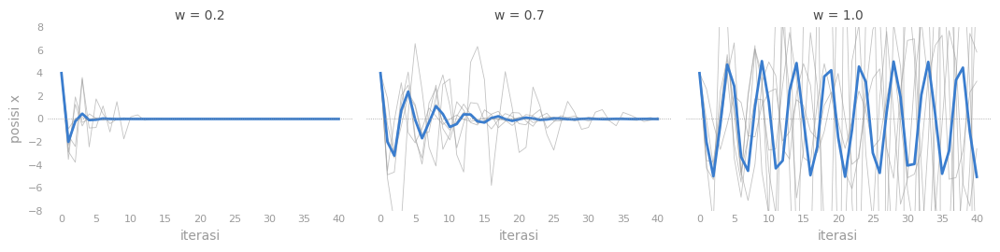

In [5]:
lib.plot_spring(ws=(0.2, 0.7, 1.0), c1=1.5, c2=1.5);

Dengan $w=0{,}2$ partikel langsung jatuh ke titik tarik: redaman kuat, hampir tanpa ayunan. Dengan $w=0{,}7$ partikel berayun beberapa kali lalu tenang. Dengan $w=1$ ayunan garis biru tidak mengecil sama sekali, dan garis abu-abu yang memakai $r$ acak keluar dari grafik. Ini yang dimaksud tidak stabil orde-2: rata-ratanya mungkin tidak meledak, tetapi sebarannya terus membesar.

### Apa yang dicegah $v_{\max}$

Kawanan lengkap dengan $w=1$ dijalankan tanpa batas kecepatan (`vmax_frac=None`) dan dengan $v_{\max}=0{,}2\times$ lebar ruang, dibandingkan dengan $w=0{,}7$ tanpa batas. Yang diukur adalah rata-rata panjang vektor kecepatan, median dari 10 seed pada Rastrigin 2D.

w=0.7, tanpa v_max       |v| iterasi 0 = 1.55, iterasi 150 = 0.0060
w=1.0, tanpa v_max       |v| iterasi 0 = 1.55, iterasi 150 = 5.6170
w=1.0, v_max=0.2·lebar   |v| iterasi 0 = 1.55, iterasi 150 = 1.8482


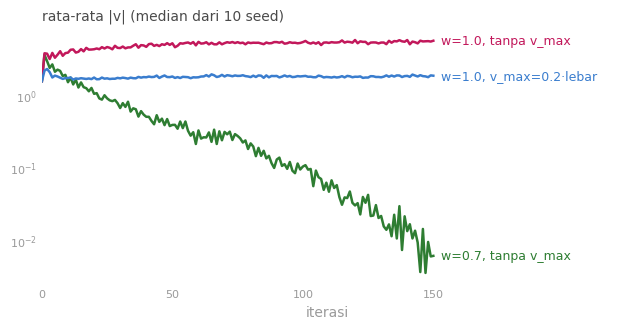

In [6]:
def mean_speed(w, vmax_frac):
    runs = [pso(rastrigin, 2, RASTRIGIN_BOUNDS, n_particles=30, iters=150, w=w, c1=1.5, c2=1.5,
                vmax_frac=vmax_frac, seed=s, record=True) for s in range(10)]
    return np.array([np.linalg.norm(r["V"], axis=2).mean(axis=1) for r in runs])


speed = {
    "w=0.7, tanpa v_max": (lib.C_RES, mean_speed(0.7, None)),
    "w=1.0, tanpa v_max": (lib.C_SOC, mean_speed(1.0, None)),
    "w=1.0, v_max=0.2·lebar": (lib.C_INERTIA, mean_speed(1.0, 0.2)),
}
for label, (_, s) in speed.items():
    print(f"{label:<24} |v| iterasi 0 = {np.median(s[:, 0]):.2f}, iterasi 150 = {np.median(s[:, -1]):.4f}")
lib.plot_speed([(label, color, s) for label, (color, s) in speed.items()]);

Dengan $w=0{,}7$ kecepatan meluruh terus, sehingga kawanan tenang tanpa bantuan $v_{\max}$. Dengan $w=1$ tanpa batas, kecepatan naik dan bertahan tinggi; satu-satunya yang menahannya adalah batas posisi, sehingga partikel terus memantul di antara dinding ruang pencarian. $v_{\max}$ menahan kecepatan di tingkat yang lebih rendah, tetapi tidak membuatnya meluruh. Jadi $v_{\max}$ mencegah ledakan, tetapi tidak menggantikan pemilihan $w$, $c_1$, $c_2$ yang stabil.

## 1.4 Pengaruh $w$, $c_1$, dan $c_2$

### Penjelasan

Enam pengaturan dibandingkan pada fungsi Rastrigin 2D dengan seed yang sama, sehingga posisi awal partikel identik di setiap panel. Perbedaan gerak hanya berasal dari parameter.

| Pengaturan | $w$ | $c_1$ | $c_2$ | Dugaan perilaku |
|---|---|---|---|---|
| seimbang | 0,7 | 1,5 | 1,5 | acuan |
| $w$ kecil | 0,2 | 1,5 | 1,5 | cepat mengumpul, mudah terjebak |
| $w$ besar | 1,0 | 1,5 | 1,5 | terus berayun, sulit mengumpul |
| kognitif dominan | 0,7 | 2,5 | 0,5 | partikel sibuk dengan pbest masing-masing |
| sosial dominan | 0,7 | 0,5 | 2,5 | semua mengejar gbest |
| $w$ turun | 0,9 → 0,4 | 1,5 | 1,5 | eksplorasi dulu, eksploitasi kemudian |

### Contoh penerapan

In [7]:
grid_runs = [pso(rastrigin, 2, RASTRIGIN_BOUNDS, n_particles=30, iters=40, w=cfg["w"], c1=cfg["c1"],
                 c2=cfg["c2"], w_end=cfg["w_end"], seed=3, record=True) for cfg in CONFIGS]
for cfg, run in zip(CONFIGS, grid_runs):
    print(f"{cfg['label']:<18} gbest f = {run['gbest_f']:.4f}")
grid_anim = lib.animate_swarms(grid_runs, rastrigin, RASTRIGIN_BOUNDS, ncols=3, panel=3.5, dpi=64, substeps=2,
                               titles=[lib.config_title(cfg) for cfg in CONFIGS])
lib.show_and_export(grid_anim, "03_parameter_grid")

seimbang           gbest f = 0.0001
w kecil            gbest f = 0.0000
w besar            gbest f = 0.0995
kognitif dominan   gbest f = 0.0420
sosial dominan     gbest f = 0.0007
w turun 0.9→0.4    gbest f = 0.0355


*Versi GIF*

![Pengaruh w, c1, c2](figures/03_parameter_grid.gif)

**Hati-hati menyimpulkan dari animasi ini.** Pada Rastrigin 2D hampir semua pengaturan menemukan pusat, dan $w$ kecil bahkan tampak paling hebat karena paling cepat mengumpul. Ruang 2D terlalu kecil: 30 partikel yang tersebar acak hampir pasti ada yang jatuh dekat lembah pusat, sehingga terjebak di minimum lokal jarang terjadi. Pada 10 dimensi jumlah minimum lokal Rastrigin meledak (sekitar $11^{10}$ lembah di dalam batas), dan di sanalah perbedaan pengaturan benar-benar terlihat. Satu run 2D juga hanya satu seed.

Untuk membandingkan secara adil, setiap pengaturan dijalankan pada **Rastrigin 10D** dengan 30 partikel, 300 iterasi, dan 30 seed yang sama (seed 0 sampai 29). Satu run berarti $30 \times 300 = 9.000$ evaluasi fungsi $f$. Jumlah evaluasi inilah ukuran anggaran yang biasa dipakai untuk membandingkan optimizer, termasuk dengan GA, karena pada masalah nyata evaluasi $f$ biasanya bagian yang paling mahal. Grafik kiri menunjukkan median nilai gbest beserta pita persentil 25–75%. Grafik kanan menunjukkan **diversitas**, yaitu rata-rata jarak partikel ke gbest. Diversitas yang jatuh ke nol berarti kawanan sudah berkumpul di satu titik dan tidak bisa menjelajah lagi.

pengaturan             Q25  median     Q75  terbaik  med@100  div akhir
seimbang              4.97    7.96    9.70     1.99     9.99   2.50e-05
w kecil              10.97   13.15   15.83     3.20    13.15   1.18e-15
w besar              36.45   42.04   45.71    23.80    49.81   4.51e+00
kognitif dominan      3.98    5.11    6.62     2.03    15.78   1.63e+00
sosial dominan        7.21   11.94   15.92     3.98    18.19   4.28e-03
w turun 0.9→0.4       3.98    6.96    9.70     2.98    22.41   8.04e-04


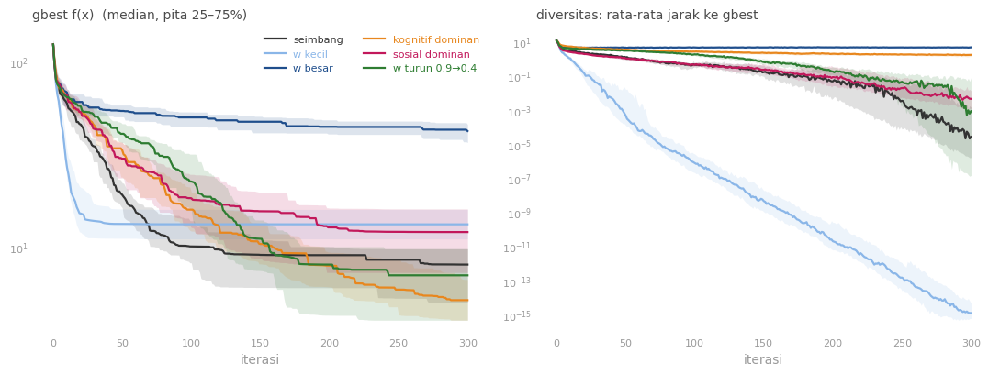

In [8]:
results = lib.run_experiment(CONFIGS, rastrigin, dim=10, bounds=RASTRIGIN_BOUNDS,
                             n_particles=30, iters=300, seeds=range(30))

print(f"{'pengaturan':<18}{'Q25':>8}{'median':>8}{'Q75':>8}{'terbaik':>9}{'med@100':>9}{'div akhir':>11}")
for cfg in CONFIGS:
    curves, div = results[cfg["name"]]
    q25, med, q75 = np.percentile(curves[:, -1], [25, 50, 75])
    print(f"{cfg['label']:<18}{q25:8.2f}{med:8.2f}{q75:8.2f}{curves[:, -1].min():9.2f}"
          f"{np.median(curves[:, 100]):9.2f}{np.median(div[:, -1]):11.2e}")
lib.plot_experiment(results, CONFIGS);

**Membaca hasilnya.** Angka di bawah diambil dari tabel di atas (Rastrigin 10D, 30 seed, nilai gbest setelah 300 iterasi).

- **$w$ besar (1,0) paling buruk**, median sekitar 42 dengan run terbaik masih di atas 23. Diversitasnya tetap sekitar 4,5 sampai akhir: kawanan tidak pernah mengumpul. Ini sesuai dengan grafik stabilitas, karena $w=1$ berada di batas daerah stabil dan osilasinya tidak teredam. Kecepatannya tertahan oleh $v_{\max}$ dan batas posisi (lihat demo $v_{\max}$ di bagian 1.3), tetapi tidak pernah meluruh, sehingga partikel tidak sempat memperhalus solusi.
- **$w$ kecil (0,2) paling cepat di awal** (median turun di bawah 20 sejak sekitar iterasi 13), tetapi berhenti membaik di sekitar 13 setelah kira-kira 50 iterasi. Diversitasnya jatuh ke orde $10^{-15}$: semua partikel menumpuk di satu titik minimum lokal sehingga tidak ada lagi yang menjelajah. Ini contoh paling jelas dari **konvergensi prematur**.
- **Sosial dominan** ($c_2=2{,}5$) juga runtuh terlalu cepat (diversitas akhir sekitar $4\times10^{-3}$) dan berakhir di median sekitar 12 dengan pita 25–75% yang lebar (7 sampai 16). Hasilnya sangat bergantung pada lembah mana yang kebetulan ditemukan gbest lebih dulu.
- **Seimbang** dan **$w$ turun** berakhir di median sekitar 8 dan 7, dengan kuartil atas yang sama (sekitar 9,7). $w$ turun lebih lambat di awal (masih sekitar 22 pada iterasi 100, sementara seimbang sudah sekitar 10), karena pada $w=0{,}9$ ia berada di luar daerah stabil dan masih menjelajah, lalu menyusul setelah $w$ mengecil.
- **Kognitif dominan** ($c_1=2{,}5$) justru memberi median akhir terbaik pada eksperimen ini, sekitar 5,1, dengan pita tersempit (4 sampai 6,6). Ia lambat di awal, tetapi diversitasnya masih sekitar 1,6 pada iterasi 300. Setiap partikel terutama memperbaiki pbest-nya sendiri, sehingga kawanan memeriksa banyak lembah sekaligus dan kurvanya masih turun saat eksperimen berhenti.

Polanya konsisten dengan dua grafik: pengaturan yang diversitasnya cepat jatuh mendekati nol (w kecil, sosial dominan) mendatar paling awal, sedangkan pengaturan yang tetap menjaga sedikit keragaman (kognitif dominan, w turun, seimbang) terus membaik lebih lama. Namun keragaman saja tidak cukup: $w$ besar paling beragam tetapi paling buruk, karena partikelnya tidak pernah sempat memperhalus solusi. Tidak ada pengaturan yang mencapai minimum global 0 dalam 300 iterasi. Peringkat ini juga khusus untuk Rastrigin 10D dengan anggaran 300 iterasi; pada fungsi lain atau anggaran lain urutannya bisa berubah.

## 1.5 Pseudocode

### Penjelasan

Versi yang dipakai di notebook ini adalah **update sinkron**: seluruh partikel bergerak dulu, baru pbest dan gbest diperbarui.

```text
PSO(f, N, T, w, c1, c2, batas [lo, hi])
    v_max ← 0.2 · (hi − lo)
    for i ← 1 to N
        x_i ← acak seragam di [lo, hi]
        v_i ← acak seragam di [−v_max, v_max]
        p_i ← x_i
    g ← argmin_{p_i} f(p_i)

    for t ← 1 to T
        for i ← 1 to N                       ▷ semua partikel memakai g yang sama
            r1, r2 ← vektor acak U(0, 1)
            v_i ← w·v_i + c1·r1⊙(p_i − x_i) + c2·r2⊙(g − x_i)
            v_i ← clip(v_i, −v_max, v_max)
            x_i ← clip(x_i + v_i, lo, hi)
        for i ← 1 to N
            if f(x_i) < f(p_i) then p_i ← x_i
        g ← argmin_{p_i} f(p_i)               ▷ gbest diperbarui sekali per iterasi
        if kriteria berhenti terpenuhi then break
    return g, f(g)
```

**Sinkron vs asinkron.** Pada update asinkron, gbest diperbarui segera setelah setiap partikel dievaluasi, sehingga partikel berikutnya dalam iterasi yang sama sudah memakai informasi terbaru. Asinkron biasanya menyebarkan informasi lebih cepat, sedangkan sinkron lebih mudah divektorisasi (semua partikel dihitung dalam satu operasi array) dan diparalelkan, serta hasilnya tidak bergantung pada urutan partikel.

**Kriteria berhenti.** Pilihan umum adalah: jumlah iterasi atau evaluasi fungsi maksimum; gbest tidak membaik lebih dari $\varepsilon$ selama $k$ iterasi; diversitas kawanan di bawah ambang tertentu; atau nilai fitness target sudah tercapai (jika minimumnya diketahui).

**Topologi tetangga (lbest).** Versi di notebook ini adalah *gbest PSO*: setiap partikel melihat partikel terbaik seluruh kawanan. Pada *lbest PSO*, $\mathbf{g}$ diganti $\mathbf{l}_i$, yaitu pbest terbaik di antara tetangga partikel $i$ saja, misalnya partikel di kiri dan kanannya pada susunan cincin. Informasi tentang daerah yang bagus menyebar lebih lambat, sehingga kawanan tidak cepat runtuh ke satu titik. Ini cara standar untuk mengurangi konvergensi prematur seperti pada pengaturan $w$ kecil dan sosial dominan di bagian 1.4. Soal 2 meminta Anda mengimplementasikannya.

**Batas kecepatan $v_{\max}$.** Tanpa batas, kecepatan bisa membesar terus ("ledakan kawanan"), terutama jika $w \ge 1$ atau $c_1+c_2$ besar. $v_{\max}$ yang terlalu besar tidak berpengaruh, sedangkan yang terlalu kecil membuat partikel merayap dan cenderung terjebak. Nilai $0{,}1$ sampai $0{,}2$ kali lebar ruang pencarian adalah titik awal yang umum. Dengan konstriksi Clerc, $v_{\max}$ secara teori tidak diperlukan, tetapi tetap berguna sebagai pengaman.

## 1.6 Implementasi dengan NumPy

### Penjelasan

Implementasi berikut mengikuti pseudocode di atas baris demi baris, tetapi tanpa perulangan per partikel. Posisi dan kecepatan seluruh kawanan disimpan dalam array berukuran `(n_particles, dim)`, sehingga satu baris NumPy meng-update semua partikel sekaligus. Perkalian `r1 * (p - x)` adalah perkalian per elemen, yaitu $r_1$ yang berbeda untuk setiap partikel dan setiap dimensi.

Fungsi tujuan `f` menerima array `(n_particles, dim)` dan mengembalikan array `(n_particles,)`.

Fungsi `pso()` di `pso_lib.py`, yang dipakai semua animasi dan eksperimen di atas, adalah fungsi yang sama ditambah tiga hal: `w_end` untuk $w$ yang turun linear, `vmax_frac=None` untuk mematikan $v_{\max}$, dan `record=True` untuk menyimpan riwayat posisi, kecepatan, pbest, gbest, serta $r_1, r_2$ yang dipakai animasi.

### Contoh penerapan

In [9]:
def pso_minimal(f, dim, bounds, n_particles=30, iters=100, w=0.7298, c1=1.49618, c2=1.49618, seed=None):
    rng = np.random.default_rng(seed)
    lo, hi = bounds
    vmax = 0.2 * (hi - lo)

    x = rng.uniform(lo, hi, (n_particles, dim))        # positions
    v = rng.uniform(-vmax, vmax, (n_particles, dim))   # velocities
    p, fp = x.copy(), f(x)                             # personal bests and their fitness
    g = p[np.argmin(fp)].copy()                        # global best

    for _ in range(iters):
        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))
        v = w * v + c1 * r1 * (p - x) + c2 * r2 * (g - x)
        v = np.clip(v, -vmax, vmax)
        x = np.clip(x + v, lo, hi)

        fx = f(x)
        better = fx < fp                               # synchronous update: after everyone moved
        p[better], fp[better] = x[better], fx[better]
        g = p[np.argmin(fp)].copy()
    return g, fp.min()

Uji singkat: pada fungsi Sphere $f(\mathbf{x})=\sum x_j^2$ yang hanya punya satu minimum, PSO harus menemukan titik nol dengan sangat teliti. Selain itu `pso_minimal` dan `pso` dari `pso_lib` harus memberi jawaban yang **persis sama** untuk seed yang sama, karena keduanya menarik angka acak dengan urutan yang sama.

In [10]:
g, fg = pso_minimal(sphere, dim=5, bounds=(-5, 5), iters=200, seed=0)
print("gbest   :", g)
print(f"f(gbest): {fg:.3e}")
assert fg < 1e-8

for seed in range(3):
    g_min, f_min = pso_minimal(rastrigin, 10, RASTRIGIN_BOUNDS, iters=300, seed=seed)
    reference = pso(rastrigin, 10, RASTRIGIN_BOUNDS, iters=300, seed=seed)
    assert np.array_equal(g_min, reference["gbest"]) and f_min == reference["gbest_f"]
    assert np.all(np.diff(reference["curve"]) <= 0)  # gbest never gets worse
print("pso_minimal sama persis dengan pso_lib.pso untuk 3 seed.")

gbest   : [-0. -0.  0.  0. -0.]
f(gbest): 1.897e-16
pso_minimal sama persis dengan pso_lib.pso untuk 3 seed.


### Eksperimen interaktif

Geser slider untuk mengubah $w$, $c_1$, dan $c_2$. Kawanan dijalankan ulang dengan seed yang sama, lalu posisinya ditampilkan pada iterasi 0, 5, 20, dan 50. Coba cari pengaturan yang membuat kawanan terjebak di lembah selain pusat, dan pengaturan yang membuat kawanan tidak pernah mengumpul.

In [11]:
import io
import ipywidgets as widgets
from IPython.display import display

sliders = {name: widgets.FloatSlider(value=value, min=lo, max=hi, step=step, description=name,
                                     continuous_update=False, readout_format=".2f")
           for name, value, lo, hi, step in [("w", 0.7, -0.2, 1.2, 0.05),
                                              ("c1", 1.5, 0.0, 3.0, 0.1),
                                              ("c2", 1.5, 0.0, 3.0, 0.1)]}
snapshot = widgets.Image(format="png")


def redraw(change=None):
    w, c1, c2 = (sliders[k].value for k in ("w", "c1", "c2"))
    run = pso(rastrigin, 2, RASTRIGIN_BOUNDS, n_particles=30, iters=50, w=w, c1=c1, c2=c2,
              seed=3, record=True)
    fig = lib.plot_snapshots(run, rastrigin, RASTRIGIN_BOUNDS, at=(0, 5, 20, 50),
                             title=f"w={w:.2f}, c₁={c1:.2f}, c₂={c2:.2f}")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=80)
    plt.close(fig)
    # An Image widget instead of interact(): large plots inside interact's Output hang headless runs.
    snapshot.value = buffer.getvalue()


for slider in sliders.values():
    slider.observe(redraw, names="value")
redraw()
display(widgets.VBox([widgets.HBox(list(sliders.values())), snapshot]))

# Latihan Soal

Lengkapi setiap `...` pada skeleton dengan ekspresi Python atau jawaban teks sesuai komentar. Untuk jawaban teks, ganti `...` dengan string dalam tanda kutip. Sel yang belum lengkap hanya menampilkan pesan; itu belum berarti jawabannya benar. Setelah lengkap, sel menjalankan pemeriksaan numerik. Buka pembahasan hanya setelah mencoba sendiri.

## Soal 1: Satu langkah

Sebuah partikel 2D berada di $\mathbf{x}=(1,\ 2)$ dengan kecepatan $\mathbf{v}=(0{,}5;\ -0{,}5)$. pbest-nya $\mathbf{p}=(2,\ 3)$ dan gbest kawanan $\mathbf{g}=(0,\ 0)$. Parameter $w=0{,}7$, $c_1=c_2=1{,}5$, dan angka acak yang keluar adalah $r_1=(0{,}2;\ 0{,}9)$, $r_2=(0{,}6;\ 0{,}1)$. Hitung tiga komponen kecepatan, kecepatan baru, dan posisi baru. Batas kecepatan tidak tercapai pada soal ini. Lalu jelaskan: apakah komponen kognitif searah dengan $\mathbf{p}-\mathbf{x}$? Mengapa?

In [12]:
x = np.array([1.0, 2.0])
v = np.array([0.5, -0.5])
p = np.array([2.0, 3.0])
g = np.array([0.0, 0.0])
w, c1, c2 = 0.7, 1.5, 1.5
r1 = np.array([0.2, 0.9])
r2 = np.array([0.6, 0.1])

# Compute each velocity term as a 2D vector.
inertia = w * v
cognitive = c1 * r1 * (p - x)
social = c2 * r2 * (g - x)

# Add the terms, then move the particle.
v_new = inertia + cognitive + social
x_new = x + v_new

# Explain whether the cognitive term points exactly along p - x, and why.
direction_explanation = (
    "Tidak tepat searah. p - x = (1, 1) menunjuk diagonal 45 derajat, tetapi komponen kognitifnya (0,3; 1,35) hampir lurus ke atas. Penyebabnya r1 diambil terpisah untuk tiap dimensi (0,2 di sumbu x dan 0,9 di sumbu y), jadi kekuatan tarikan tiap sumbu berbeda. Tandanya tetap sama dengan p - x, sehingga partikel tetap tertarik mendekati pbest di setiap sumbu, hanya saja tidak lurus ke titik pbest."
)

if any(value is Ellipsis for value in (inertia, cognitive, social, v_new, x_new, direction_explanation)):
    print("Soal 1 belum lengkap. Ganti seluruh ... dengan kode atau penjelasan.")
else:
    print("inersia  :", inertia)
    print("kognitif :", cognitive)
    print("sosial   :", social)
    print("v baru   :", v_new)
    print("x baru   :", x_new)
    assert np.allclose(v_new, inertia + cognitive + social)
    assert np.allclose(x_new, x + v_new)
    assert np.allclose(v_new, [-0.25, 0.7]), "Periksa lagi salah satu komponen."
    print("Angka benar. Penjelasan:", direction_explanation)

inersia  : [ 0.35 -0.35]
kognitif : [0.3  1.35]
sosial   : [-0.9 -0.3]
v baru   : [-0.25  0.7 ]
x baru   : [0.75 2.7 ]
Angka benar. Penjelasan: Tidak tepat searah. p - x = (1, 1) menunjuk diagonal 45 derajat, tetapi komponen kognitifnya (0,3; 1,35) hampir lurus ke atas. Penyebabnya r1 diambil terpisah untuk tiap dimensi (0,2 di sumbu x dan 0,9 di sumbu y), jadi kekuatan tarikan tiap sumbu berbeda. Tandanya tetap sama dengan p - x, sehingga partikel tetap tertarik mendekati pbest di setiap sumbu, hanya saja tidak lurus ke titik pbest.


<details>
<summary>Klik untuk melihat pembahasan Soal 1</summary>

```python
inertia = w * v                  # [ 0.35, -0.35]
cognitive = c1 * r1 * (p - x)    # 1.5 * [0.2, 0.9] * [1, 1]  = [ 0.3,  1.35]
social = c2 * r2 * (g - x)       # 1.5 * [0.6, 0.1] * [-1, -2] = [-0.9, -0.3]
v_new = inertia + cognitive + social   # [-0.25, 0.7]
x_new = x + v_new                       # [ 0.75, 2.7]
```

$\mathbf{p}-\mathbf{x}=(1,\ 1)$ menunjuk diagonal 45°, tetapi komponen kognitifnya $(0{,}3;\ 1{,}35)$ hampir tegak ke atas. Penyebabnya, $r_1$ berbeda per dimensi: sumbu $x$ hanya mendapat 20% tarikan, sumbu $y$ 90%. Komponen kognitif tetap berada di kuadran yang sama dengan $\mathbf{p}-\mathbf{x}$ (tidak pernah menjauhi pbest pada sumbu mana pun), tetapi arahnya tidak tepat ke pbest. Ini yang terlihat pada animasi bagian 1.2.

</details>

## Soal 2: Topologi cincin (lbest)

Ganti gbest dengan **lbest cincin**: partikel $i$ hanya melihat pbest dirinya sendiri dan dua tetangganya, $i-1$ dan $i+1$ (partikel 0 bertetangga dengan partikel terakhir). Sosialnya menjadi $c_2 r_2(\mathbf{l}_i-\mathbf{x}_i)$, dengan $\mathbf{l}_i$ pbest terbaik di antara tiga partikel itu.

1. Lengkapi `ring_best(p, fp)` yang mengembalikan array `(n_particles, dim)` berisi $\mathbf{l}_i$ untuk setiap partikel, tanpa perulangan Python. Petunjuk: `np.roll`.
2. Lengkapi baris update kecepatan pada `pso_ring`.
3. Bandingkan `pso_ring` dengan `pso_minimal` pada Rastrigin 10D, 10 seed, untuk 300 dan 1000 iterasi (9.000 dan 30.000 evaluasi $f$). Apakah cincin selalu lebih baik? Jelaskan hasilnya dengan konsep diversitas.

In [13]:
def ring_best(p, fp):
    """Return, for each particle, the best pbest among itself and its two ring neighbours."""
    # Build the neighbour indices (left, self, right) and pick the one with the lowest fp.
    idx = np.arange(len(fp))
    neighbours = np.stack([np.roll(idx, 1), idx, np.roll(idx, -1)], axis=1)  # (n, 3): left, self, right
    best = neighbours[idx, np.argmin(fp[neighbours], axis=1)]                 # winner index per particle
    return p[best]


def pso_ring(f, dim, bounds, n_particles=30, iters=300, w=0.7298, c1=1.49618, c2=1.49618, seed=None):
    rng = np.random.default_rng(seed)
    lo, hi = bounds
    vmax = 0.2 * (hi - lo)
    x = rng.uniform(lo, hi, (n_particles, dim))
    v = rng.uniform(-vmax, vmax, (n_particles, dim))
    p, fp = x.copy(), f(x)
    for _ in range(iters):
        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))
        l = ring_best(p, fp)
        # Velocity update with the ring neighbourhood best l instead of g.
        v = w * v + c1 * r1 * (p - x) + c2 * r2 * (l - x)
        v = np.clip(v, -vmax, vmax)
        x = np.clip(x + v, lo, hi)
        fx = f(x)
        better = fx < fp
        p[better], fp[better] = x[better], fx[better]
    return p[np.argmin(fp)], fp.min()


# Explain the comparison after looking at the printed medians.
ring_explanation = (
    "Tidak selalu. Pada 300 iterasi hasilnya hampir sama (median gbest 8,46, cincin 8,48, cincin lebih baik di 5/10 seed). Pada 1000 iterasi cincin unggul (median 4,97 vs 7,46, lebih baik di 6/10 seed) walau masih kalah di beberapa seed, karena gbest nyaris berhenti membaik sedangkan cincin terus turun. Sebabnya ada di diversitas: pada gbest semua partikel langsung tertarik ke satu titik terbaik, diversitas cepat habis, dan kawanan terjebak di minimum lokal. Pada cincin, kabar tentang lembah bagus merambat pelan dari tetangga ke tetangga, jadi kawanan tetap menyebar lebih lama dan masih sempat menemukan lembah lain. Cincin memang lebih lambat di awal, tetapi lebih jarang terjebak, sehingga keunggulannya baru terlihat bila iterasinya cukup banyak."
)

p_test = np.arange(5.0)[:, None]
fp_test = np.array([3.0, 1.0, 4.0, 0.0, 5.0])
if ring_best(p_test, fp_test) is Ellipsis or ring_explanation is Ellipsis:
    print("Soal 2 belum lengkap. Ganti seluruh ... dengan kode atau penjelasan.")
else:
    assert np.array_equal(ring_best(p_test, fp_test)[:, 0], [1, 1, 3, 3, 3]), "ring_best salah"
    for iters in (300, 1000):
        f_gbest = [pso_minimal(rastrigin, 10, RASTRIGIN_BOUNDS, iters=iters, seed=s)[1] for s in range(10)]
        f_ring = [pso_ring(rastrigin, 10, RASTRIGIN_BOUNDS, iters=iters, seed=s)[1] for s in range(10)]
        wins = sum(r < g for r, g in zip(f_ring, f_gbest))
        print(f"{iters:>4} iterasi: median gbest = {np.median(f_gbest):.2f}, "
              f"median cincin = {np.median(f_ring):.2f}, cincin lebih baik pada {wins}/10 seed")
    print("Penjelasan:", ring_explanation)

 300 iterasi: median gbest = 8.46, median cincin = 8.48, cincin lebih baik pada 5/10 seed
1000 iterasi: median gbest = 7.46, median cincin = 4.97, cincin lebih baik pada 6/10 seed
Penjelasan: Tidak selalu. Pada 300 iterasi hasilnya hampir sama (median gbest 8,46, cincin 8,48, cincin lebih baik di 5/10 seed). Pada 1000 iterasi cincin unggul (median 4,97 vs 7,46, lebih baik di 6/10 seed) walau masih kalah di beberapa seed, karena gbest nyaris berhenti membaik sedangkan cincin terus turun. Sebabnya ada di diversitas: pada gbest semua partikel langsung tertarik ke satu titik terbaik, diversitas cepat habis, dan kawanan terjebak di minimum lokal. Pada cincin, kabar tentang lembah bagus merambat pelan dari tetangga ke tetangga, jadi kawanan tetap menyebar lebih lama dan masih sempat menemukan lembah lain. Cincin memang lebih lambat di awal, tetapi lebih jarang terjebak, sehingga keunggulannya baru terlihat bila iterasinya cukup banyak.


<details>
<summary>Klik untuk melihat pembahasan Soal 2</summary>

```python
def ring_best(p, fp):
    idx = np.arange(len(fp))
    neighbours = np.stack([np.roll(idx, 1), idx, np.roll(idx, -1)])   # (3, n): left, self, right
    winner = neighbours[np.argmin(fp[neighbours], axis=0), idx]
    return p[winner]

# inside pso_ring
v = w * v + c1 * r1 * (p - x) + c2 * r2 * (l - x)
```

`np.roll(idx, 1)[i]` bernilai `i-1` dan otomatis membungkus 0 ke `n-1`. `fp[neighbours]` berukuran `(3, n)`, sehingga `argmin(axis=0)` memilih baris pemenang untuk setiap partikel.

Pada percobaan kami, dengan 300 iterasi kedua versi hampir sama (median sekitar 8,5 untuk keduanya, cincin lebih baik pada separuh seed). Dengan 1000 iterasi cincin unggul cukup jelas (median sekitar 5 dibanding sekitar 7,5). Pada gbest, begitu satu partikel menemukan lembah bagus, seluruh kawanan langsung tertarik ke sana, diversitas cepat habis, dan setelah itu pencarian praktis berhenti. Pada cincin, kabar tentang lembah bagus perlu beberapa iterasi untuk merambat dari tetangga ke tetangga, sehingga bagian kawanan yang jauh masih menjelajah lembah lain. Akibatnya cincin lebih lambat di awal tetapi lebih jarang terjebak, dan keunggulannya baru terlihat jika anggaran iterasinya cukup panjang. Jadi jawabannya: tidak selalu; tergantung anggaran.

</details>

## Ringkasan dan Referensi

| Komponen | Rumus | Peran |
|---|---|---|
| Inersia | $w\,\mathbf{v}_i$ | mempertahankan arah, mengatur eksplorasi |
| Kognitif | $c_1 r_1(\mathbf{p}_i-\mathbf{x}_i)$ | menarik ke pengalaman sendiri, menjaga keragaman |
| Sosial | $c_2 r_2(\mathbf{g}-\mathbf{x}_i)$ | menarik ke temuan kawanan, mempercepat konvergensi |
| Stabilitas | $-1<w<1,\ 0<c_1+c_2<\frac{24(1-w^2)}{7-5w}$ | memastikan kawanan tidak meledak |
| Clerc | $w\approx0{,}7298,\ c_1=c_2\approx1{,}49618$ | titik awal yang aman |

1. J. Kennedy dan R. Eberhart, "Particle swarm optimization," *Proc. ICNN'95*, vol. 4, hlm. 1942–1948, 1995.
2. Y. Shi dan R. Eberhart, "A modified particle swarm optimizer," *Proc. IEEE CEC*, hlm. 69–73, 1998.
3. R. Poli, "Mean and variance of the sampling distribution of particle swarm optimizers during stagnation," *IEEE Trans. Evol. Comput.*, vol. 13, no. 4, hlm. 712–721, 2009.
4. M. Clerc dan J. Kennedy, "The particle swarm — explosion, stability, and convergence in a multidimensional complex space," *IEEE Trans. Evol. Comput.*, vol. 6, no. 1, hlm. 58–73, 2002.
